# Tutorial 1: Flow Development Length: 
#### How much straight channel do I need?

##### Microfluidic engineering | Dr. Francisco Tovar

**Goal:** Understand the physical problem, estimate $L_{FD}$ using a published correlation, and explore flow rate, viscosity and Reynolds number. **No CFD in this tutorial.**

## 1. Start with the engineering problem

One of the first challenges in microfluidics is **interfacing the external world with the small world of the microfluidic device**.

**syringe → tubing → connector → inlet port → microchannel**

Changes in size also occur inside the device:

**channel → contraction → sensing region → expansion → another channel**

At each transition the cross-sectional area may change. For incompressible flow,

$$Q=UA,\qquad U=\frac{Q}{A}$$

where $Q$ is flow rate, $U$ is **cross-sectional mean velocity**, and $A$ is area. At fixed $Q$, smaller area means higher mean velocity.


<p align="center">
  <img src="images/transitions.png" width="800">
</p>

But the velocity **profile** does not instantly adjust to the new geometry.

> **After a change in channel size or geometry, how much distance is required before the flow stops changing significantly?**

This motivates the **flow development length**, $L_{FD}$.

## 2. What develops?

The no-slip condition makes velocity zero at stationary walls. Viscous effects reshape the velocity profile downstream until its **shape** changes negligibly with distance.


<p align="center">
  <img src="images/flow_development.png" width="800">
</p>

## 3. Why should an engineer care?

One word: **Reproducibility.**

Reproducibility in your own experiments, and reproducibility across different studies.

If the flow is still developing when it reaches the region of interest, apparently identical experiments may not actually be performed under the same local flow conditions. Differences in inlet geometry, connectors, channel dimensions, flow rate, or fluid properties can change the development length and therefore the conditions experienced by the sample.

**Too short:** The region of interest may experience changing velocity distributions, shear rates, wall shear stresses, and trajectories. Assuming a particular shear rate or flow condition could therefore be wrong.

**Unnecessarily long:** More footprint, hydraulic resistance, pressure drop, internal volume, fabrication area, and pumping requirements. For biological samples, additional channel length also increases residence time and contact with device materials. This may matter in PDMS devices, where absorption of small molecules and changes in their effective concentration have been experimentally demonstrated [1–3].

**Design question:** How much entrance length is justified for the intended experiment?

Not every device needs fully developed flow. What matters is knowing and controlling the flow condition under which the experiment is performed.

### References

1. Toepke, M.W. & Beebe, D.J. (2006). *PDMS absorption of small molecules and consequences in microfluidic applications*. Lab on a Chip, 6, 1484–1486.
2. Wang, J.D. et al. (2012). *Quantitative analysis of molecular absorption into PDMS microfluidic channels*. Annals of Biomedical Engineering, 40, 1862–1873.
3. van Meer, B.J. et al. (2017). *Small molecule absorption by PDMS in the context of drug response bioassays*. Biochemical and Biophysical Research Communications, 482, 323–328.

## 4. How can we estimate $L_{FD}$?

There are several approaches. **This tutorial uses a published correlation only.** A later tutorial will introduce CFD as another approximate model, not as ground truth.

Li, Huang & Wu (2019) report, for **square microchannels**,

$$\boxed{\frac{L_{FD}}{D_h}=\frac{0.28}{1+0.1Re}+0.0537Re}$$

Their study covers **$0.5\le Re\le50$** and hydraulic diameters of 100–200 µm; the correlation fitted their data within approximately 15.2%. We will use it to teach the calculation, including an illustrative **rectangular** channel, but **its accuracy for that rectangle is not established**.

**Assumptions and risks:** The calculation uses a representative mean velocity and a homogeneous, Newtonian, incompressible, laminar fluid with constant properties. Mean velocity is **not** a uniform velocity profile. Geometry, inlet conditions and the criterion for development may differ from the published study. A correlation is an **estimate under assumptions**, not a measurement.

**Reference:** Li, H., Huang, B., & Wu, M. (2019), *Experimental and Numerical Investigations on the Flow Characteristics within Hydrodynamic Entrance Regions in Microchannels*, **Micromachines 10**, 317. DOI: 10.3390/mi10050317.

## 5. What information do we need?

For a rectangular channel of width $w$ and height $h$:

$$A=wh,\qquad D_h=\frac{2wh}{w+h}.$$

Then

$$U=\frac{Q}{A},\qquad Re=\frac{\rho U D_h}{\mu}.$$

We must specify **flow rate $Q$, width $w$, height $h$, density $\rho$, and dynamic viscosity $\mu$**. Convert to SI units before calculating.

## 6. Worked example: calculate the length step by step

Assume $w=200\ \mu\mathrm{m}$, $h=85\ \mu\mathrm{m}$, $Q=100\ \mu\mathrm{L/min}$, $\rho=1000\ \mathrm{kg/m^3}$ and $\mu=1\ \mathrm{mPa\cdot s}$.

**1. Area:**
$$A=(200\times10^{-6})(85\times10^{-6})=1.70\times10^{-8}\ \mathrm{m^2}.$$

**2. Hydraulic diameter:**
$$D_h=\frac{2(200)(85)}{200+85}=119.3\ \mu\mathrm{m}.$$

**3. Convert flow rate:**
$$Q=\frac{100\times10^{-9}}{60}=1.667\times10^{-9}\ \mathrm{m^3/s}.$$

**4. Mean velocity:**
$$U=\frac{1.667\times10^{-9}}{1.70\times10^{-8}}=0.0980\ \mathrm{m/s}.$$

**5. Reynolds number:**
$$Re=\frac{(1000)(0.0980)(119.3\times10^{-6})}{0.001}=11.7.$$

**6. Correlation:**
$$\frac{L_{FD}}{D_h}=\frac{0.28}{1+0.1(11.7)}+0.0537(11.7)\approx0.757.$$

**7. Estimated length:**
$$L_{FD}\approx0.757(119.3\ \mu\mathrm{m})\approx90\ \mu\mathrm{m}=0.090\ \mathrm{mm}.$$

**Interpretation:** A correlation-based teaching estimate, **not a validated inlet length** for this rectangular geometry.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Five editable inputs
w_um, h_um = 200.0, 85.0
Q_uL_min, rho, mu_mPa_s = 100.0, 1000.0, 1.0
w, h = w_um*1e-6, h_um*1e-6
A = w*h
Dh = 2*w*h/(w+h)
Q = Q_uL_min*1e-9/60
mu = mu_mPa_s*1e-3
U = Q/A
Re = rho*U*Dh/mu

def correlation(Re):
    """Li et al. 2019, Eq. 7: tested for square microchannels, Re 0.5–50."""
    return 0.28/(1+0.1*np.asarray(Re)) + 0.0537*np.asarray(Re)

LFD = correlation(Re)*Dh
print(f"Area: {A:.3e} m² | Dh: {Dh*1e6:.1f} µm")
print(f"Mean U: {U:.4f} m/s | Re: {Re:.2f}")
print(f"Estimated LFD: {LFD*1e3:.4f} mm ({LFD*1e6:.1f} µm)")

Area: 1.700e-08 m² | Dh: 119.3 µm
Mean U: 0.0980 m/s | Re: 11.70
Estimated LFD: 0.0903 mm (90.3 µm)


## 7. Explore flow rates and viscosities

Now keep geometry and density fixed. Vary $Q$ and $\mu$, and use **the same published correlation** for each case.

**Predict first:** What happens to $Re$ when $Q$ increases? What happens when viscosity increases? What does that imply for estimated $L_{FD}$?

In [35]:
flow_rates = np.array([10,25,50,100])  # µL/min
viscosities = np.array([1,2,4,8])              # mPa·s

rows = []

for viscosity in viscosities:
    for flow in flow_rates:

        q = flow * 1e-9 / 60                    # µL/min -> m³/s
        u = q / A                               # m/s
        re = rho * u * Dh / (viscosity * 1e-3)

        lfd_over_Dh = float(correlation(re))
        lfd_um = lfd_over_Dh * Dh * 1e6         # m -> µm

        rows.append({
            "Q [µL/min]": flow,
            "μ [mPa·s]": viscosity,
            "U [m/s]": u,
            "Re": re,
            "LFD [µm]": lfd_um,
            "LFD/Dh": lfd_over_Dh,
            "Within Re 0.5–50": 0.5 <= re <= 50
        })

df = pd.DataFrame(rows)

display(df.round(4))

print(
    "Within published Re range:",
    df["Within Re 0.5–50"].sum(),
    "of",
    len(df)
)

,Q [µL/min],μ [mPa·s],U [m/s],Re,LFD [µm],LFD/Dh,Within Re 0.5–50
0,10,1,0.0098,1.1696,37.3985,0.3135,True
1,25,1,0.0245,2.9240,44.5781,0.3737,True
2,50,1,0.0490,5.8480,58.5413,0.4907,True
3,100,1,0.0980,11.6959,90.3239,0.7571,True
4,10,2,0.0098,0.5848,35.3044,0.2959,True
5,25,2,0.0245,1.4620,38.5088,0.3228,True
6,50,2,0.0490,2.9240,44.5781,0.3737,True
7,100,2,0.0980,5.8480,58.5413,0.4907,True
8,10,4,0.0098,0.2924,34.3277,0.2877,False
9,25,4,0.0245,0.7310,35.8110,0.3002,True


Within published Re range: 13 of 16


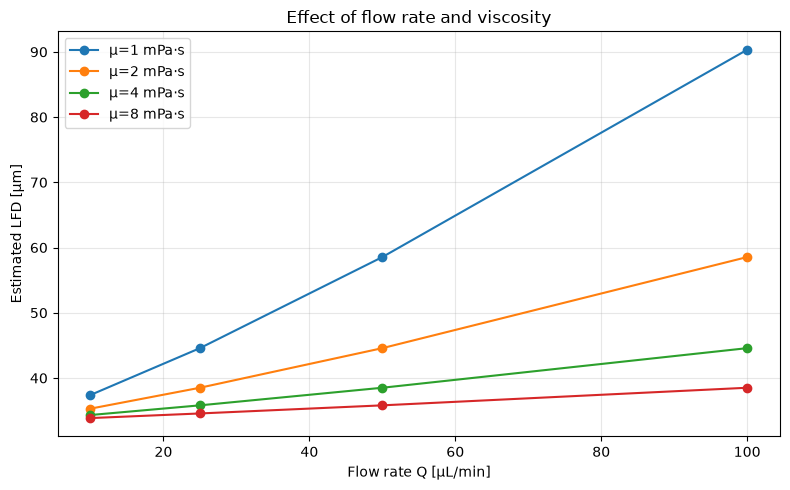

In [36]:
fig,ax=plt.subplots(figsize=(8,5))
for viscosity,g in df.groupby("μ [mPa·s]"):
    ax.plot(g["Q [µL/min]"],g["LFD [µm]"],marker="o",label=f"μ={viscosity:g} mPa·s")
ax.set(xlabel="Flow rate Q [µL/min]",ylabel="Estimated LFD [µm]",title="Effect of flow rate and viscosity")
ax.grid(alpha=.3);ax.legend();plt.tight_layout();plt.show()

## 8. Can Reynolds number describe the effect of both flow rate and viscosity?

So far, we have changed flow rate and viscosity independently and obtained different values of $L_{FD}$.

However, both variables appear in the Reynolds number:

$$
Re=\frac{\rho QD_h}{\mu A}.
$$

This means that different combinations of flow rate and viscosity can produce the **same Reynolds number**.

For example, increasing both $Q$ and $\mu$ by the same factor leaves $Re$ unchanged.

If the correlation describes the development length through

$$
\frac{L_{FD}}{D_h}=f(Re),
$$

then two operating conditions with the same $Re$ will also have the same predicted $L_{FD}/D_h$.

We can see this by plotting all our flow-rate and viscosity combinations against Reynolds number.

Some points will appear directly on top of each other. They are not missing: different combinations of $Q$ and $\mu$ have produced the same $Re$ and therefore the same predicted $L_{FD}/D_h$.

This shows why Reynolds number is useful: several apparently different operating conditions can represent the same balance between inertia and viscosity.

In this example, this behaviour follows directly from the published correlation. With experimental or independently calculated data, we would need to test whether the same relationship is observed.

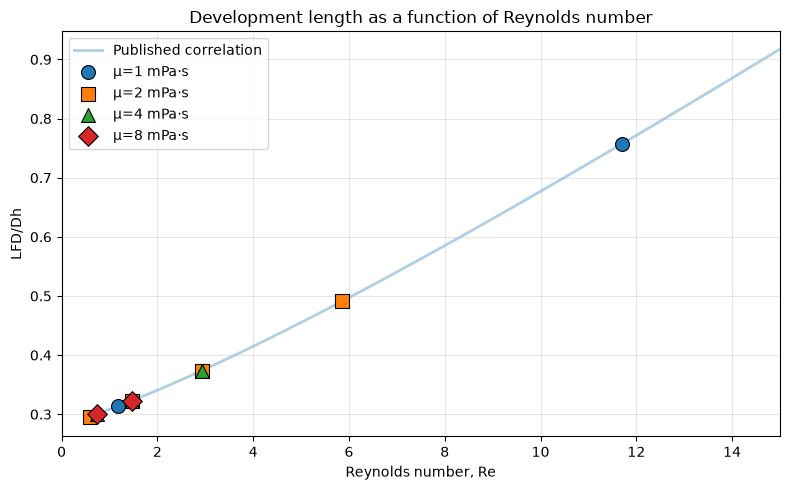

In [37]:
fig, ax = plt.subplots(figsize=(8,5))

markers = ["o", "s", "^", "D"]

# Correlation BEHIND the points
re_plot = re_axis[re_axis <= 15]

ax.plot(
    re_plot,
    correlation(re_plot),
    alpha=0.35,
    linewidth=2,
    label="Published correlation",
    zorder=1
)

# Points ON TOP of the correlation
for (viscosity, g), marker in zip(
    df.groupby("μ [mPa·s]"), markers
):
    valid = g[(g["Re"] >= 0.5) & (g["Re"] <= 15)]

    ax.scatter(
        valid["Re"],
        valid["LFD/Dh"],
        marker=marker,
        s=100,
        edgecolors="black",
        linewidths=0.8,
        label=f"μ={viscosity:g} mPa·s",
        zorder=3
    )

ax.set(
    xlabel="Reynolds number, Re",
    ylabel="LFD/Dh",
    title="Development length as a function of Reynolds number"
)

ax.set_xlim(0,15)
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.show()

## 10. What does this mean for the device?

A correlation gives an **initial engineering estimate**, not a guaranteed minimum length. Before choosing the device length, ask:

1. Which operating condition gives the largest estimated $L_{FD}$?
2. Are all the predictions within the correlation's published $Re$ range?
3. Does the channel geometry match the study (square versus rectangular)?
4. What extra footprint, residence time and pressure drop would a longer entrance section create?
5. Does the experiment actually require fully developed flow?

The ideal mean-flow residence time over a length $L$ is $t=L/U$. This is an average transit-time estimate, not the residence time of every particle.

In [38]:
# Compare the residence time of a candidate length and one five times longer
candidate_um = float(df["LFD [µm]"].max())
for factor in (1,5):
    length_m = factor*candidate_um*1e-3
    t_ms = 1e3*length_m/U  # mean velocity from the worked example
    print(f"Length = {factor} × max predicted LFD = {factor*candidate_um:.1f} µm")
    print(f"Mean transit time at worked-example Q = {t_ms:.2f} ms")
    print()
print("These values are illustrative; no safety factor or validity guarantee is implied.")

Length = 1 × max predicted LFD = 90.3 µm
Mean transit time at worked-example Q = 921.30 ms

Length = 5 × max predicted LFD = 451.6 µm
Mean transit time at worked-example Q = 4606.52 ms

These values are illustrative; no safety factor or validity guarantee is implied.


## 11. Your engineering exercise

1. Change the flow-rate and viscosity arrays. Which condition has the largest $L_{FD}$ estimate?
2. Find two combinations of $Q$ and $\mu$ that produce similar $Re$. Do they produce similar estimated $L_{FD}$?
3. Change the channel height. What happens to $U$, $D_h$, $Re$ and $L_{FD}$?
4. Identify any cases outside the published $Re$ range. Why should they be treated cautiously?
5. Explain why using $U=Q/A$ does **not** assume uniform velocity everywhere.
6. Explain why an accurate numerical answer can still be an unsuitable engineering design estimate.

### Take-home message

**Start with the physical connection and the engineering need. Calculate with stated assumptions. Explore operating conditions. Then look for simpler relationships.**

**Next tutorial (not included here):** CFD-based evaluation of velocity-profile development and the assumptions and numerical checks involved.